# 05 - End-to-end prediction

**Goal:** run the served pipeline on three photos, with the API's own code: a C3PI test photo
(`src/models/predict.py`: detector -> crops -> classifier), a medicine box (OCR and the brand
table, `backend/app/boxes.py`) and an off-topic picture, which must be refused. Models:
`models/detector.onnx` and `models/classifier.onnx` (published from the Model Registry).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")


import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

In [2]:
from app.config import Settings
from app.gallery import load_gallery
from app.inference import PillScanner
from src.models.predict import predict_image

settings = Settings()
scanner = PillScanner.from_dir(settings.models_dir, conf=settings.scan_detection_confidence)
names = pd.read_csv(ROOT / "config" / "pill_classes.csv").set_index("class_id").name

## 1. A pill photo

A photo of the demo gallery: C3PI v2 test split, never seen in training by the served models.

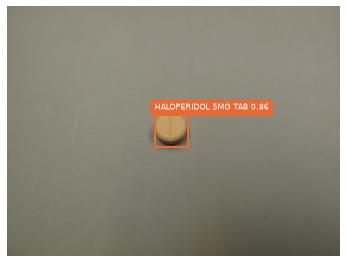

,class,probability
0,HALOPERIDOL 5MG TAB,0.862
1,Amiodarone Hydrochloride,0.016
2,HALOPERIDOL 1MG TAB,0.009
3,LAMICTAL,0.008
4,Hydrochlorothiazide,0.006


In [3]:
photo = load_gallery(
    settings.demo_gallery_file,
    settings.demo_split_file,
    settings.demo_holdout_file,
    settings.demo_images_dir,
    settings.demo_gradcam_dir,
)[0]
result = predict_image(scanner, photo.file)
image = Image.open(photo.file)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(image)
for pill in result["pills"]:
    b = pill["box"]
    top = pill["top5"][0]
    ax.add_patch(
        plt.Rectangle(
            (b["x1"], b["y1"]),
            b["x2"] - b["x1"],
            b["y2"] - b["y1"],
            fill=False,
            color="#eb6834",
            linewidth=2,
        )
    )
    ax.text(
        b["x1"],
        b["y1"] - 40,
        f"{names[top['class_id']]} {top['probability']:.2f}",
        color="white",
        backgroundcolor="#eb6834",
        fontsize=8,
    )
ax.axis("off")
plt.show()
pd.DataFrame(
    [
        {"class": names[c["class_id"]], "probability": round(c["probability"], 3)}
        for c in result["pills"][0]["top5"]
    ]
)

In [4]:
print("expected:", names[photo.class_id])
print("detection confidence:", round(result["pills"][0]["confidence"], 3))
print("timings (ms):", result["timings"])

expected: HALOPERIDOL 5MG TAB
detection confidence: 0.953
timings (ms): {'detection_ms': 351.0, 'classification_ms': 123.9, 'inference_ms': 474.9, 'server_ms': 713.0}


## 2. A medicine box and an off-topic picture

The pill models only know C3PI pills, so the scanner also reads the printed text (RapidOCR)
and decides the kind of photo (`decide_kind`): `box`, `pill` or `unknown` (refused).
`run_samples` is the code of the OCR benchmark (`src/models/ocr/evaluate.py`); RxNav is off.

[WARNING] 2026-11-23 23:27:29,420 [RapidOCR] main.py:164: The text detection result is empty


*panadol_500mg_fi.jpg: kind = box*

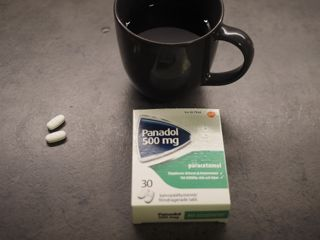

*astronaut.png: kind = unknown*

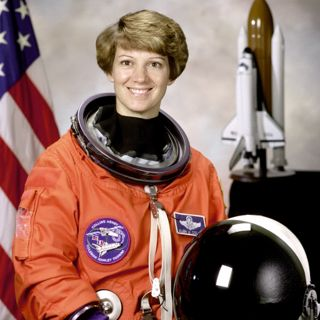

,image,kind,brand,ingredients found,best pill detection,letters read
0,panadol_500mg_fi.jpg,box,Panadol,[acetaminophen],0.5994,118
1,astronaut.png,unknown,,[],0.3124,0


In [5]:
from app.boxes import KindThresholds, RapidOcrEngine
from src.models.ocr.evaluate import matcher, off_topic_samples, run_samples, web_samples

box = next(s for s in web_samples() if s.brand == "Panadol")
off_topic = next(s for s in off_topic_samples() if s.image.name == "astronaut.png")
outcomes = run_samples(
    RapidOcrEngine(threads=4), [box, off_topic], matcher(), scanner, KindThresholds()
)
for sample, outcome in zip((box, off_topic), outcomes, strict=True):
    show_image(sample.image, f"{sample.image.name}: kind = {outcome.kind}", width=320)
pd.DataFrame(
    [
        {
            "image": o.image,
            "kind": o.kind,
            "brand": o.brand,
            "ingredients found": o.found,
            "best pill detection": o.pill_confidence,
            "letters read": o.text_chars,
        }
        for o in outcomes
    ]
)

**Takeaway:** the pill is found and named with its probability; the box is recognised from its
printed text and linked to its active ingredient; the off-topic picture is refused instead of
being given a pill name.